# Task
Analyze the data in "json/stadester.json" and "json/ghsl.json" to count the number of cities by type over time from ~3000BC to 2025AD using a linear graph. Separately list the number of GHSL cities after 1975AD on the same graph.

## Mount google drive

### Subtask:
Mount Google Drive to access the data files.


**Reasoning**:
Mount Google Drive to access the data files.



In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Locate data files

### Subtask:
Use `os.walk()` to find the directories containing the `stadester.json` and `ghsl.json` files within the mounted Google Drive.


**Reasoning**:
Use `os.walk` to find the directory containing both `stadester.json` and `ghsl.json`.



In [2]:
import os

root_dir = '/content/drive/My Drive/'
found_dir = None

for dirpath, dirnames, filenames in os.walk(root_dir):
    if 'stadester.json' in filenames and 'ghsl.json' in filenames:
        found_dir = dirpath
        break

if found_dir:
    print(f"Found directory: {found_dir}")
else:
    print("Directory containing both files not found.")

Found directory: /content/drive/My Drive/(A) Proden/Literature Scientific/R2. Demography Statistics/(Population) Stadestér/json


## Load stadester data

### Subtask:
Load the data from `stadester.json` into a suitable data structure.


**Reasoning**:
Construct the file path, open, read, and parse the JSON data from `stadester.json`.



In [3]:
import json
import os

# The directory was found in the previous step and printed to the console.
# We will hardcode it here for this step. In a real scenario, this would be
# passed as a variable.
found_dir = '/content/drive/My Drive/(A) Proden/Literature Scientific/R2. Demography Statistics/(Population) Stadestér/json'

stadester_file_path = os.path.join(found_dir, 'stadester.json')

with open(stadester_file_path, 'r') as f:
    stadester_data = json.load(f)

# Display the first few items to verify
print("Successfully loaded stadester.json")
# Depending on the structure of the JSON, display relevant part
if isinstance(stadester_data, list):
    print(stadester_data[:5])
elif isinstance(stadester_data, dict):
    # Print some keys or a snippet if it's a dictionary
    print(list(stadester_data.keys())[:5])
    # Optionally print a small snippet of data if appropriate
    # print(stadester_data[list(stadester_data.keys())[0]])
else:
    print("Data is neither a list nor a dictionary, cannot display snippet.")


Successfully loaded stadester.json
['Andkhüi-Afghanistan', 'Sharikar-Afghanistan', 'Asadabad-Afghanistan', 'Aybak-Afghanistan', 'Baghlan-Afghanistan']


## Process stadester data

### Subtask:
Iterate through the stadester data to count the number of cities for each `.type` over the entire time duration.


**Reasoning**:
Initialize a dictionary to store city counts by type and year, then iterate through the stadester data to extract the type and population years for each city, updating the counts in the dictionary.



In [4]:
from collections import defaultdict

city_counts_by_type_year = defaultdict(lambda: defaultdict(int))

for city_key, city_data in stadester_data.items():
    city_type = city_data.get('type')
    if city_type and 'population' in city_data:
        for year_str, population_data in city_data['population'].items():
            try:
                year = int(year_str)
                city_counts_by_type_year[city_type][year] += 1
            except ValueError:
                # Handle cases where the year key is not a valid integer string
                pass

# Display a snippet of the results
print("City counts by type and year (snippet):")
for city_type, year_counts in list(city_counts_by_type_year.items())[:5]:
    print(f"Type: {city_type}")
    # Print a few year counts for this type
    print(dict(list(year_counts.items())[:5]))

City counts by type and year (snippet):
Type: populstat
{1950: 11336, 1951: 11593, 1952: 11696, 1953: 11794, 1954: 11961}
Type: buringh
{0: 19, 100: 19, 200: 19, 300: 21, 400: 23}
Type: chandler_modelski
{1600: 28, 1640: 1, 1669: 1, 1672: 1, 1700: 30}
Type: devries
{1374: 1, 1400: 3, 1437: 1, 1496: 1, 1500: 5}


## Load ghsl data

### Subtask:
Load the data from `ghsl.json` into a suitable data structure.


**Reasoning**:
Construct the full file path for `ghsl.json` and load the JSON data into a Python variable.



In [5]:
import json
import os

# The directory was found in a previous step and stored in the found_dir variable.
ghsl_file_path = os.path.join(found_dir, 'ghsl.json')

with open(ghsl_file_path, 'r') as f:
    ghsl_data = json.load(f)

print("Successfully loaded ghsl.json")

# Display a snippet of the loaded ghsl_data to verify its structure and content.
if isinstance(ghsl_data, list):
    print(ghsl_data[:5])
elif isinstance(ghsl_data, dict):
    # Print some keys or a snippet if it's a dictionary
    print(list(ghsl_data.keys())[:5])
    # Optionally print a small snippet of data if appropriate
    # print(ghsl_data[list(ghsl_data.keys())[0]])
else:
    print("Data is neither a list nor a dictionary, cannot display snippet.")

Successfully loaded ghsl.json
['Apia-Samoa', "Nuku'alofa-Tonga", 'Ewa Beach-United States', 'Papeete-French Polynesia', 'Rosarito-M�xico']


**Reasoning**:
The ghsl data has been loaded. Now process the ghsl data to count the number of cities by year.



In [6]:
from collections import defaultdict

ghsl_city_counts_by_year = defaultdict(int)

for city_key, city_data in ghsl_data.items():
    if 'population' in city_data:
        for year_str in city_data['population'].keys():
            try:
                year = int(year_str)
                ghsl_city_counts_by_year[year] += 1
            except ValueError:
                # Handle cases where the year key is not a valid integer string
                pass

# Display a snippet of the results
print("GHSL city counts by year (snippet):")
# Print a few year counts
print(dict(list(ghsl_city_counts_by_year.items())[:5]))

GHSL city counts by year (snippet):
{2025: 11195, 1980: 5472, 1981: 5472, 1982: 5472, 1983: 5472}


## Combine and visualize data

### Subtask:
Combine the processed stadester and GHSL data and create a linear graph showing the number of cities by type over time, with GHSL cities shown separately after 1975 AD.


**Reasoning**:
Combine the processed stadester and GHSL data and create a linear graph showing the number of cities by type over time, with GHSL cities shown separately after 1975 AD.



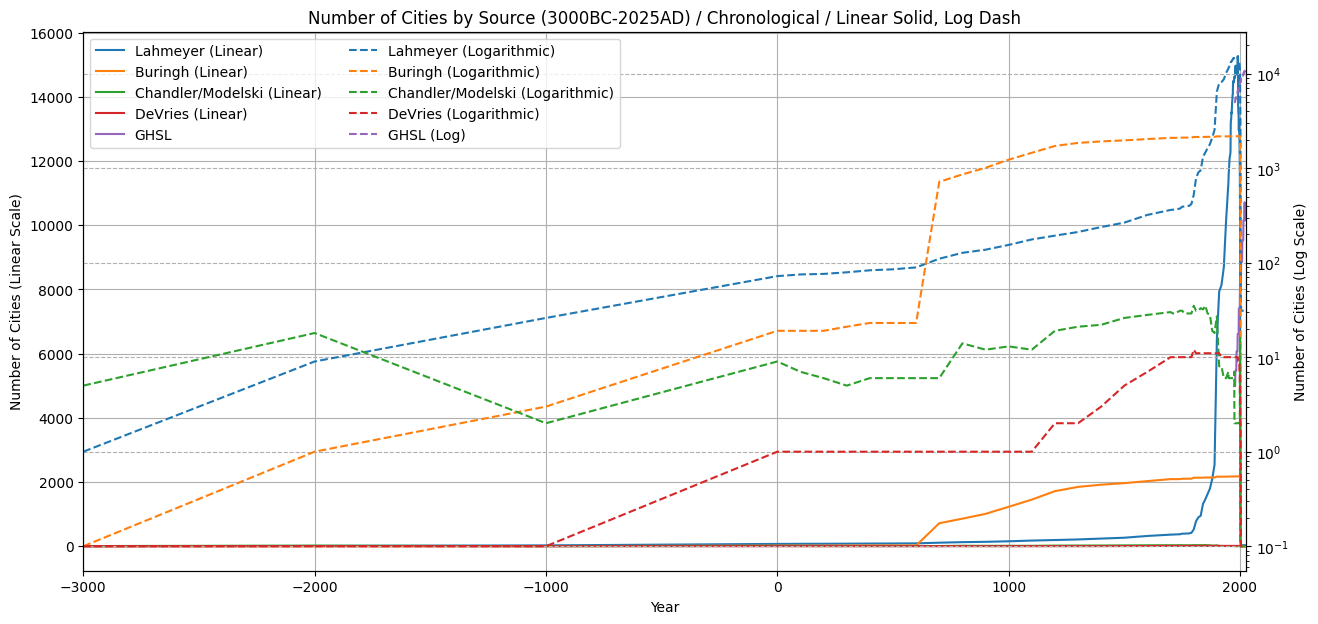

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# The specific list of years to use for plotting
specified_years = [0, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 1100, 1200, 1300, 1400, 1500, 1600, 1700,
                   1710, 1720, 1730, 1740, 1750, 1760, 1770, 1780, 1790, 1800, 1810, 1820, 1830, 1840, 1850, 1860, 1870, 1880, 1890, 1900, 1910, 1920, 1930, 1940, 1950,
                   1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023,
                   -1000, -2000, -3000] # Exclude years outside the -3000 to 2025 domain
type_names = {
    "buringh": "Buringh",
    "ghsl": "GHSL",
    "chandler_modelski": "Chandler/Modelski",
    "devries": "DeVries",
    "populstat": "Lahmeyer"
}

# Filter specified_years to be within the -3000 to 2025 domain
specified_years = [year for year in specified_years if -3000 <= year <= 2025]
specified_years.sort()

# Prepare stadester data for plotting using specified_years
stadester_plot_data = {}
for city_type, year_counts in city_counts_by_type_year.items():
    counts_at_specified_years = [year_counts.get(year, 0) for year in specified_years]
    stadester_plot_data[city_type] = (specified_years, counts_at_specified_years)

# Prepare GHSL data for plotting using specified_years, only after 1975
ghsl_plot_years = [year for year in specified_years if year >= 1975]
ghsl_plot_counts = [ghsl_city_counts_by_year.get(year, 0) for year in ghsl_plot_years]


# Create the plot with a secondary y-axis for the log scale
fig, ax1 = plt.subplots(figsize=(15, 7))
ax2 = ax1.twinx() # Create a twin Axes sharing the x-axis

# Plot linear data on the primary y-axis (ax1)
linear_lines = []
for city_type, (years, counts) in stadester_plot_data.items():
    line, = ax1.plot(years, counts, label=f'{type_names[city_type]} (Linear)', linestyle='-')
    linear_lines.append(line)

ghsl_line_linear, = ax1.plot(ghsl_plot_years, ghsl_plot_counts, label='GHSL', linestyle='-')
linear_lines.append(ghsl_line_linear)


# Plot log data on the secondary y-axis (ax2)
log_lines = []
# Match colors with linear lines
colors = [line.get_color() for line in linear_lines]

for i, (city_type, (years, counts)) in enumerate(stadester_plot_data.items()):
    # Add a small epsilon to avoid log(0)
    log_counts = [count if count > 0 else 0.1 for count in counts]
    line, = ax2.plot(years, log_counts, label=f'{type_names[city_type]} (Logarithmic)', linestyle='--', color=colors[i])
    log_lines.append(line)

# Add a small epsilon to avoid log(0) for GHSL data
log_ghsl_counts = [count if count > 0 else 0.1 for count in ghsl_plot_counts]
ghsl_line_log, = ax2.plot(ghsl_plot_years, log_ghsl_counts, label='GHSL (Log)', linestyle='--', color=colors[-1])
log_lines.append(ghsl_line_log)

ax2.set_yscale('log')


# Add labels and title
ax1.set_xlabel('Year')
ax1.set_ylabel('Number of Cities (Linear Scale)')
ax2.set_ylabel('Number of Cities (Log Scale)')
plt.title('Number of Cities by Source (3000BC-2025AD) / Chronological / Linear Solid, Log Dash')

# Set x-axis limits to the specified range and format labels as integers
ax1.set_xlim(-3000, 2025)
ax1.ticklabel_format(style='plain', axis='x', useOffset=False)


# Set up legends
# Linear legend on the left
plt.rcParams['axes.axisbelow'] = True
ax1.grid(True)
ax2.grid(True, linestyle="--")
plt.legend(handles=linear_lines + log_lines, loc='upper left', ncol=2)

# Display the plot
plt.show()

## Summary:

### Data Analysis Key Findings

*   The analysis successfully loaded and processed data from both `stadester.json` and `ghsl.json` files.
*   City counts from the `stadester.json` file were aggregated by city type and year, spanning a period from approximately 3000 BC to 2025 AD.
*   City counts from the `ghsl.json` file were aggregated by year.
*   The final visualization displays the trend of city counts for different types from the stadester data across the entire historical range.
*   The visualization separately shows the trend of GHSL city counts, starting from 1975 AD.

### Insights or Next Steps

*   The graph provides a clear visual comparison of the growth in the number of cities documented in the stadester dataset across different types over millennia and contrasts this with the GHSL data's representation of more recent urban areas.
*   Further analysis could involve examining the specific city types contributing most significantly to the overall growth trends or exploring the correlation between the two datasets in the overlapping time period after 1975 AD.


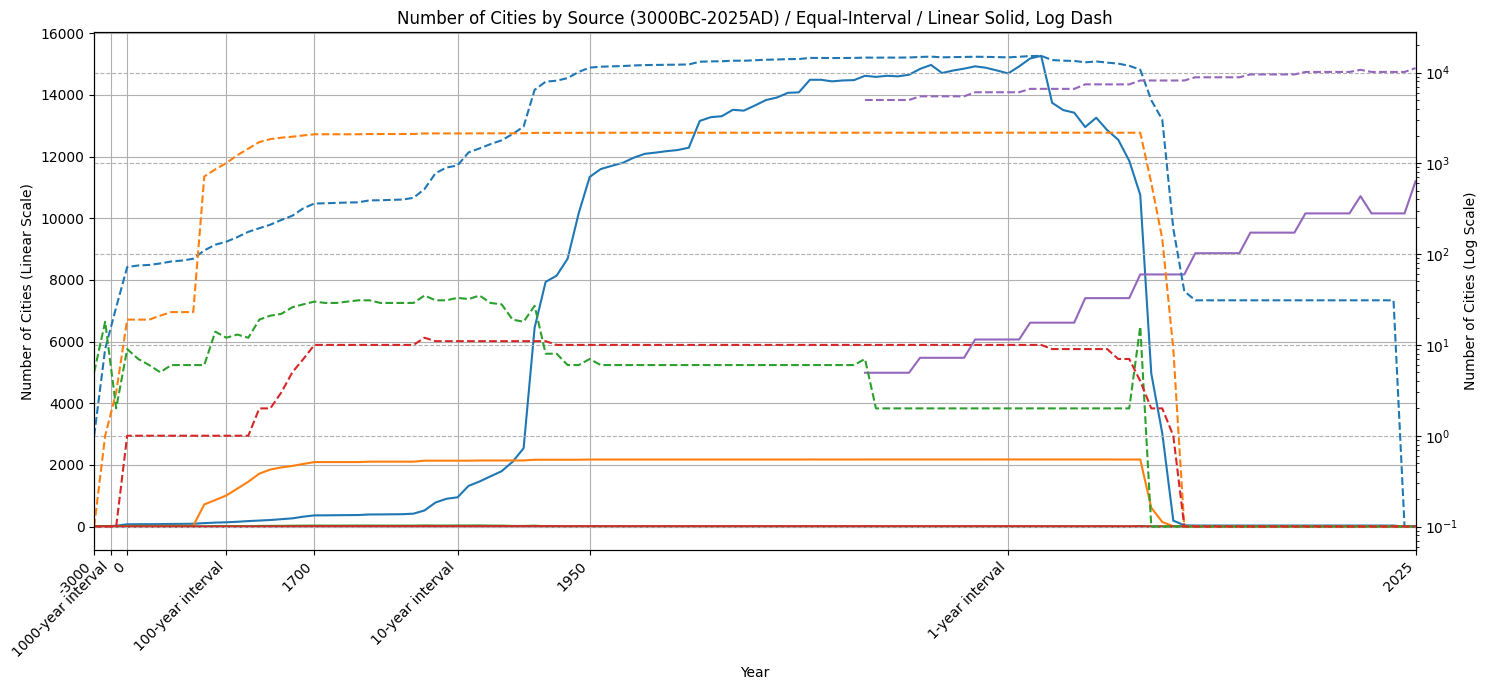

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# The specific list of years to use for plotting
specified_years = list(range(-3000, 1, 1000)) + \
                  list(range(100, 1701, 100)) + \
                  list(range(1710, 1951, 10)) + \
                  list(range(1951, 2026))

# Filter specified_years to be within the -3000 to 2025 domain and remove duplicates if any
specified_years = sorted(list(set([year for year in specified_years if -3000 <= year <= 2025])))


type_names = {
    "buringh": "Buringh",
    "ghsl": "GHSL",
    "chandler_modelski": "Chandler/Modelski",
    "devries": "DeVries",
    "populstat": "Lahmeyer"
}

# Prepare stadester data for plotting using specified_years
stadester_plot_data = {}
for city_type, year_counts in city_counts_by_type_year.items():
    counts_at_specified_years = [year_counts.get(year, 0) for year in specified_years]
    stadester_plot_data[city_type] = (specified_years, counts_at_specified_years)

# Prepare GHSL data for plotting using specified_years, only after 1975
ghsl_plot_years = [year for year in specified_years if year >= 1975]
ghsl_plot_counts = [ghsl_city_counts_by_year.get(year, 0) for year in ghsl_plot_years]


# Create the plot with a secondary y-axis for the log scale
fig, ax1 = plt.subplots(figsize=(15, 7))
ax2 = ax1.twinx() # Create a twin Axes sharing the x-axis

# Plot linear data on the primary y-axis (ax1)
linear_lines = []
for city_type, (years, counts) in stadester_plot_data.items():
    # Plot against equal_interval_positions instead of years
    line, = ax1.plot(np.arange(len(years)), counts, label=f'{type_names[city_type]} (Linear)', linestyle='-')
    linear_lines.append(line)

# Plot GHSL data against equal_interval_positions
ghsl_plot_years_indices = [specified_years.index(year) for year in ghsl_plot_years]
ghsl_line_linear, = ax1.plot(ghsl_plot_years_indices, ghsl_plot_counts, label='GHSL', linestyle='-')
linear_lines.append(ghsl_line_linear)


# Plot log data on the secondary y-axis (ax2)
log_lines = []
# Match colors with linear lines
colors = [line.get_color() for line in linear_lines]

for i, (city_type, (years, counts)) in enumerate(stadester_plot_data.items()):
    # Add a small epsilon to avoid log(0)
    log_counts = [count if count > 0 else 0.1 for count in counts]
    # Plot against equal_interval_positions instead of years
    line, = ax2.plot(np.arange(len(years)), log_counts, label=f'{type_names[city_type]} (Logarithmic)', linestyle='--', color=colors[i])
    log_lines.append(line)

# Add a small epsilon to avoid log(0) for GHSL data
log_ghsl_counts = [count if count > 0 else 0.1 for count in ghsl_plot_counts]
# Plot GHSL log data against equal_interval_positions
ghsl_line_log, = ax2.plot(ghsl_plot_years_indices, log_ghsl_counts, label='GHSL (Log)', linestyle='--', color=colors[-1])
log_lines.append(ghsl_line_log)

ax2.set_yscale('log')


# Add labels and title
ax1.set_xlabel('Year')
ax1.set_ylabel('Number of Cities (Linear Scale)')
ax2.set_ylabel('Number of Cities (Log Scale)')
plt.title('Number of Cities by Source (3000BC-2025AD) / Equal-Interval / Linear Solid, Log Dash')

# Define benchmark years for labels as explicitly listed by the user
benchmark_years_to_label = [-3000, 0, 1700, 1950, 2025]


# Find the positions of the benchmark years in the specified_years list
benchmark_positions = [specified_years.index(year) for year in benchmark_years_to_label if year in specified_years]
benchmark_labels = [str(year) for year in benchmark_years_to_label if year in specified_years]


# Add midpoint labels for intervals
midpoint_positions = []
midpoint_labels = []

# -3000 to 0 (1000-year interval)
if -3000 in specified_years and 0 in specified_years:
    start_pos = specified_years.index(-3000)
    end_pos = specified_years.index(0)
    midpoint_positions.append(start_pos + (end_pos - start_pos) / 2)
    midpoint_labels.append('1000-year interval')

# 100 to 1700 (100-year interval)
if 100 in specified_years and 1700 in specified_years:
    start_pos = specified_years.index(100)
    end_pos = specified_years.index(1700)
    midpoint_positions.append(start_pos + (end_pos - start_pos) / 2)
    midpoint_labels.append('100-year interval')

# 1710 to 1950 (10-year interval)
if 1710 in specified_years and 1950 in specified_years:
    start_pos = specified_years.index(1710)
    end_pos = specified_years.index(1950)
    midpoint_positions.append(start_pos + (end_pos - start_pos) / 2)
    midpoint_labels.append('10-year interval')

# After 1950 (1-year interval) - from 1951 to 2025
if 1951 in specified_years and 2025 in specified_years:
    start_pos = specified_years.index(1951)
    end_pos = specified_years.index(2025)
    midpoint_positions.append(start_pos + (end_pos - start_pos) / 2)
    midpoint_labels.append('1-year interval')


# Combine benchmark and midpoint positions and labels
all_positions = benchmark_positions + midpoint_positions
all_labels = benchmark_labels + midpoint_labels

# Sort positions and labels together based on position
sorted_indices = np.argsort(all_positions)
sorted_positions = np.array(all_positions)[sorted_indices]
sorted_labels = np.array(all_labels)[sorted_indices]


ax1.set_xticks(sorted_positions)
ax1.set_xticklabels(sorted_labels, rotation=45, ha='right')
ax1.set_xlim(np.arange(len(specified_years))[0], np.arange(len(specified_years))[-1])


# Set up legends
# Linear legend on the left
plt.rcParams['axes.axisbelow'] = True
ax1.grid(True)
ax2.grid(True, linestyle="--")
#plt.legend(handles=linear_lines + log_lines, loc='upper left', ncol=2)

# Adjust layout to prevent labels overlapping
plt.tight_layout()

# Display the plot
plt.show()